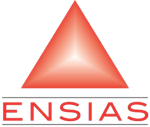

# TP 2 — Validation et évaluation des modèles

**Module :** Introduction au Machine Learning
**Enseignant :** Prof. Aissam BERRAHOU — ENSIAS, Université Mohammed V de Rabat
**Niveau :** 2e année cycle ingénieur
**Durée estimée :** 2 heures
**Support associé :** Lecture 2 — Évaluation des modèles

## 1. Objectifs pédagogiques

*Ce TP prolonge le cours : vous allez refaire sur machine les calculs vus en séance, puis passer à un vrai jeu de données.*

1. Recalculer **à la main** la matrice de confusion et les métriques de l'exemple des slides.
2. Comparer **hold-out** et **validation croisée k-fold**.
3. Produire un **rapport de classification** sur un jeu de données réel.
4. Construire une **courbe ROC** point par point, puis avec scikit-learn, et calculer l'**AUC**.
5. Comprendre pourquoi l'exactitude est trompeuse avec des classes **déséquilibrées**.

## 2. Rappel théorique

*Avant de coder, un rapide rappel des formules dont nous aurons besoin.*

| | Prédit positif | Prédit négatif |
|---|---|---|
| **Réel positif** | TP | FN |
| **Réel négatif** | FP | TN |

$$\text{Exactitude} = \frac{TP+TN}{n} \quad \text{Précision} = \frac{TP}{TP+FP} \quad \text{Rappel} = \frac{TP}{TP+FN} \quad F_1 = \frac{2PR}{P+R}$$

Courbe ROC : $TPR = \frac{TP}{TP+FN}$ en fonction de $FPR = \frac{FP}{FP+TN}$ quand le seuil varie ; AUC = aire sous la courbe.

## 3. Import des bibliothèques

*On charge d'abord les outils. Tout le TP n'utilise que NumPy, pandas, Matplotlib et scikit-learn.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, roc_curve, auc, ConfusionMatrixDisplay)

## 4. Exemple jouet : le test de dépistage

*Reprenons le test de dépistage du cours : que valent vraiment ses 85 % de réussite ?*

100 patients : 50 malades (1), 50 sains (0). On reconstruit les vecteurs réels et prédits :

In [2]:
y_vrai = np.array([1] * 50 + [0] * 50)
y_pred = np.array([1] * 40 + [0] * 10 +      # malades : 40 détectés (TP), 10 manqués (FN)
                  [1] * 5 + [0] * 45)        # sains : 5 fausses alertes (FP), 45 corrects (TN)
TP = np.sum((y_vrai == 1) & (y_pred == 1)); FN = np.sum((y_vrai == 1) & (y_pred == 0))
FP = np.sum((y_vrai == 0) & (y_pred == 1)); TN = np.sum((y_vrai == 0) & (y_pred == 0))
print(f"TP = {TP}  FN = {FN}  FP = {FP}  TN = {TN}")

TP = 40  FN = 10  FP = 5  TN = 45


### 4.1 Les métriques à la main

*D'abord à la main, pour bien comprendre ce que mesure chaque chiffre.*

In [3]:
exactitude = (TP + TN) / len(y_vrai)
precision = TP / (TP + FP)
rappel = TP / (TP + FN)
specificite = TN / (TN + FP)
f1 = 2 * precision * rappel / (precision + rappel)
print(f"exactitude = {exactitude:.3f}  précision = {precision:.3f}  rappel = {rappel:.3f}")
print(f"spécificité = {specificite:.3f}  F1 = {f1:.3f}")

exactitude = 0.850  précision = 0.889  rappel = 0.800
spécificité = 0.900  F1 = 0.842


### 4.2 Vérification avec scikit-learn

*scikit-learn trouve-t-il les mêmes valeurs que nous ?*

In [4]:
print(confusion_matrix(y_vrai, y_pred, labels=[1, 0]))    # [[TP FN] [FP TN]]
print("exactitude :", accuracy_score(y_vrai, y_pred))
print("précision  :", round(precision_score(y_vrai, y_pred), 3))
print("rappel     :", recall_score(y_vrai, y_pred))
print("F1         :", round(f1_score(y_vrai, y_pred), 3))

[[40 10]
 [ 5 45]]
exactitude : 0.85
précision  : 0.889
rappel     : 0.8
F1         : 0.842


### 4.3 Le piège de l'exactitude : classes déséquilibrées

*Un modèle peut-il afficher 99 % d'exactitude… sans jamais trouver un seul malade ?*

990 sains, 10 malades, et un « modèle » qui répond toujours « sain » :

In [5]:
y_vrai_des = np.array([0] * 990 + [1] * 10)
y_pred_des = np.zeros(1000, dtype=int)                    # prédit toujours 0
print("exactitude :", accuracy_score(y_vrai_des, y_pred_des))       # 0.99 !
print("rappel     :", recall_score(y_vrai_des, y_pred_des))         # 0 : aucun malade détecté

exactitude : 0.99
rappel     : 0.0


### 4.4 Matrice de confusion multi-classes (exemple des slides)

*Comment lire une matrice de confusion quand il y a trois classes ?*

In [6]:
M = np.array([[50, 5, 2], [3, 40, 10], [4, 6, 45]])       # lignes = réel, colonnes = prédit
precision_c = np.diag(M) / M.sum(axis=0)                   # par colonne
rappel_c = np.diag(M) / M.sum(axis=1)                      # par ligne
f1_c = 2 * precision_c * rappel_c / (precision_c + rappel_c)
print("exactitude :", round(np.trace(M) / M.sum(), 3))
pd.DataFrame({"précision": precision_c, "rappel": rappel_c, "F1": f1_c}, index=["A", "B", "C"]).round(3)

exactitude : 0.818


,précision,rappel,F1
A,0.877,0.877,0.877
B,0.784,0.755,0.769
C,0.789,0.818,0.804


## 5. Courbe ROC pas à pas

*À partir de quel score déclare-t-on un patient malade ? Testons tous les seuils.*

8 patients avec un score de risque (exemple des slides) :

In [7]:
scores = np.array([0.95, 0.85, 0.70, 0.60, 0.45, 0.30, 0.20, 0.10])
etiquettes = np.array([1, 1, 0, 1, 0, 1, 0, 0])            # 1 = malade
lignes = []
for seuil in [1.0] + list(scores):
    pred = scores >= seuil                                  # positif si score ≥ seuil
    tp, fp = np.sum(pred & (etiquettes == 1)), np.sum(pred & (etiquettes == 0))
    lignes.append({"seuil": seuil, "TPR": tp / 4, "FPR": fp / 4})
roc = pd.DataFrame(lignes); roc

,seuil,TPR,FPR
0,1.00,0.00,0.00
1,0.95,0.25,0.00
2,0.85,0.50,0.00
3,0.70,0.50,0.25
4,0.60,0.75,0.25
5,0.45,0.75,0.50
6,0.30,1.00,0.50
7,0.20,1.00,0.75
8,0.10,1.00,1.00


AUC à la main : 0.8125    AUC scikit-learn : 0.8125


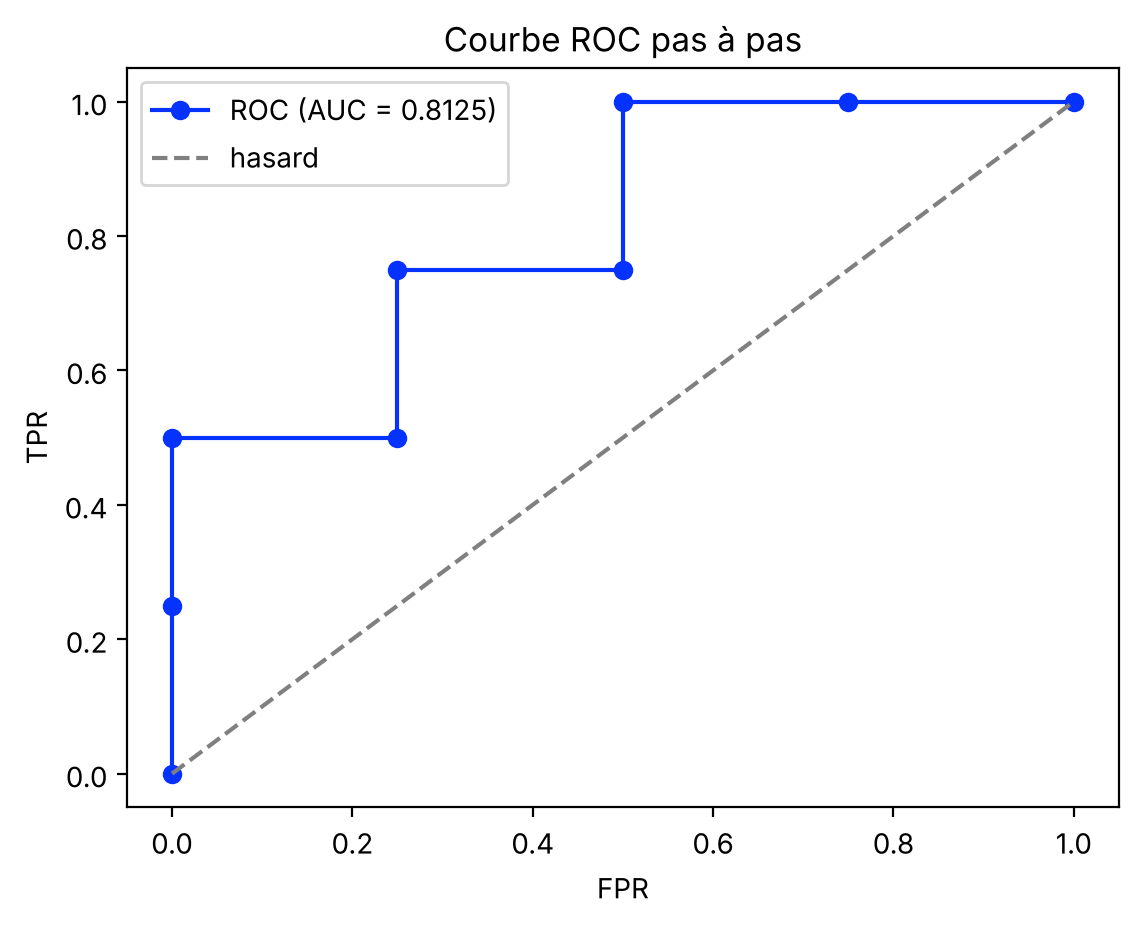

In [8]:
aire = np.sum(np.diff(roc["FPR"]) * roc["TPR"].values[1:])  # somme de rectangles
fpr, tpr, _ = roc_curve(etiquettes, scores)
print("AUC à la main :", aire, "   AUC scikit-learn :", auc(fpr, tpr))
plt.step(roc["FPR"], roc["TPR"], where="post", marker="o", color="#0532FF", label=f"ROC (AUC = {aire:.4f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="hasard")
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend(); plt.title("Courbe ROC pas à pas"); plt.show()

## 6. Cas pratique : la base Breast Cancer

*Passons à de vraies données médicales : 569 tumeurs à classer.*

### 6.1 Hold-out

In [9]:
cancer = load_breast_cancer()
X, y = cancer.data, cancer.target                           # 1 = bénigne, 0 = maligne
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
modele = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(X_train, y_train)
print("Exactitude hold-out :", round(modele.score(X_test, y_test), 3))

Exactitude hold-out : 0.956


Le résultat dépend du découpage : changeons seulement la graine aléatoire.

In [10]:
for graine in range(5):
    Xa, Xt, ya, yt = train_test_split(X, y, test_size=0.2, random_state=graine, stratify=y)
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(5)).fit(Xa, ya)
    print(f"graine {graine} : exactitude = {m.score(Xt, yt):.3f}")

graine 0 : exactitude = 0.956
graine 1 : exactitude = 0.974
graine 2 : exactitude = 0.982


graine 3 : exactitude = 0.974


graine 4 : exactitude = 0.982


### 6.2 Validation croisée k-fold

*Comment obtenir un score qui ne dépend pas d'un tirage chanceux ?*

In [11]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores_cv = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(5)), X_train, y_train, cv=kfold)
print("scores par pli :", scores_cv.round(3))
print(f"moyenne = {scores_cv.mean():.3f}  écart-type = {scores_cv.std():.3f}")

scores par pli : [0.967 0.967 0.945 0.956 0.978]
moyenne = 0.963  écart-type = 0.011


### 6.3 Évaluation : rapport de classification

*Où le modèle se trompe-t-il, et dans quel sens ?*

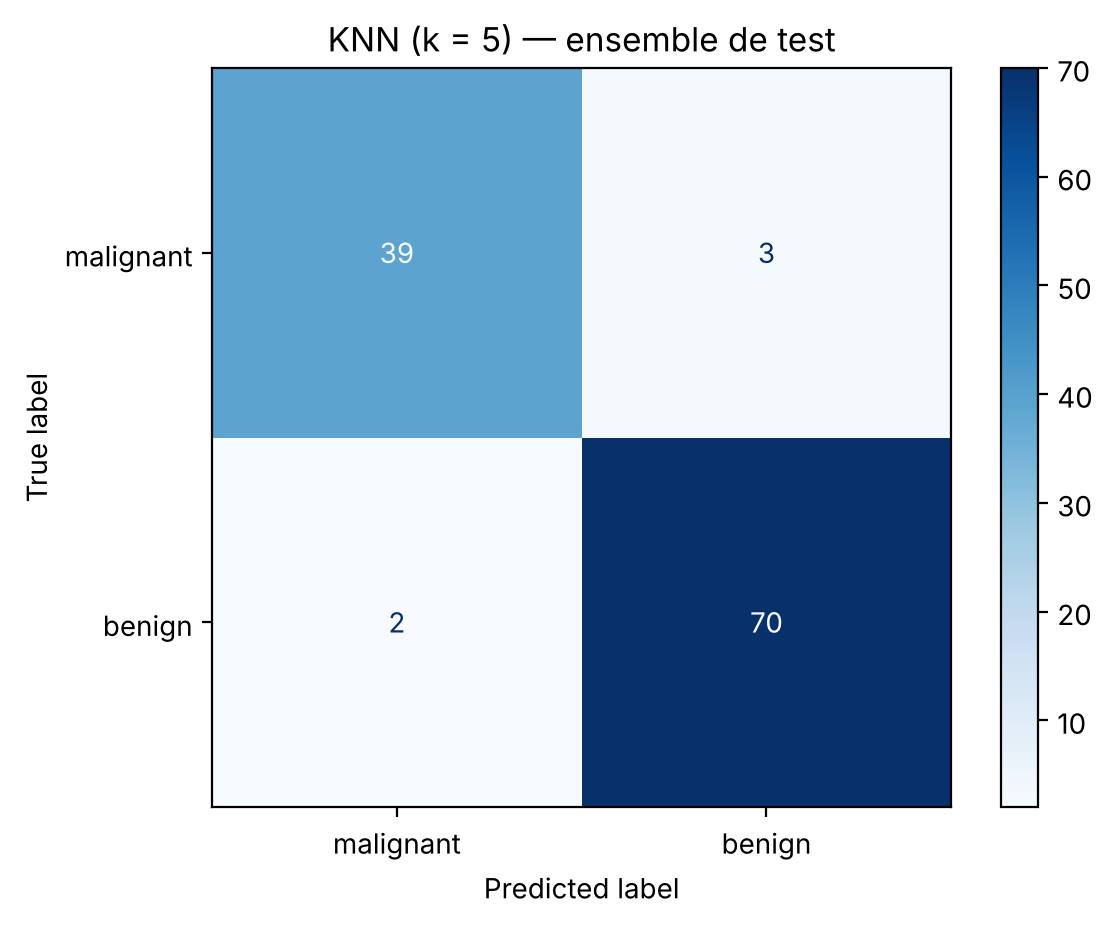

              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [12]:
y_pred = modele.predict(X_test)
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=cancer.target_names).plot(cmap="Blues")
plt.title("KNN (k = 5) — ensemble de test"); plt.show()
print(classification_report(y_test, y_pred, target_names=cancer.target_names))

## 7. Influence des hyperparamètres : seuil de décision et nombre de plis

*Deux modèles, deux courbes ROC : lequel choisir ?*

### 7.1 Courbe ROC de deux modèles

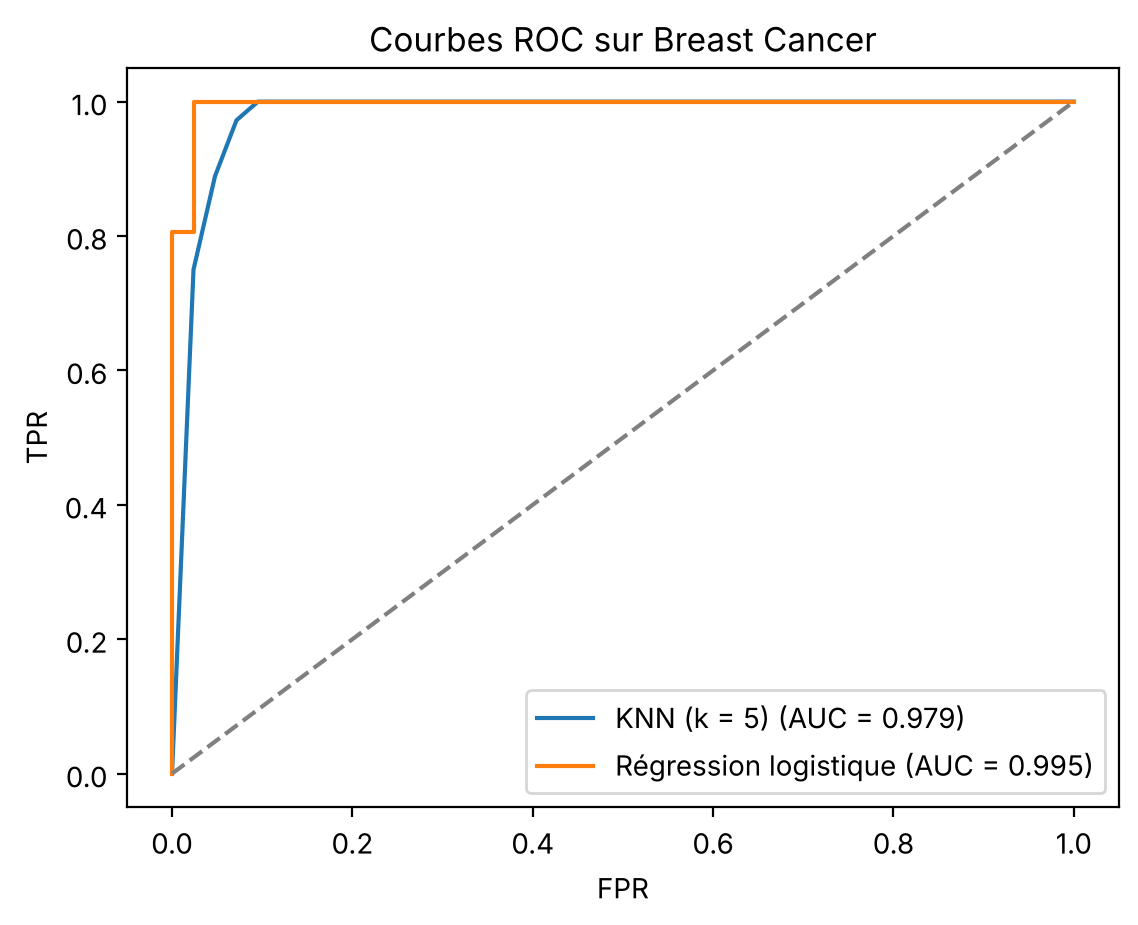

In [13]:
logreg = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)
for nom, m in [("KNN (k = 5)", modele), ("Régression logistique", logreg)]:
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{nom} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend(); plt.title("Courbes ROC sur Breast Cancer"); plt.show()

### 7.2 Précision et rappel selon le seuil

*Que gagne-t-on, et que perd-on, en déplaçant le seuil ?*

In [14]:
probas = logreg.predict_proba(X_test)[:, 1]
for seuil in [0.3, 0.5, 0.7, 0.9]:
    pred = (probas >= seuil).astype(int)
    print(f"seuil {seuil} : précision = {precision_score(y_test, pred):.3f}  rappel = {recall_score(y_test, pred):.3f}")

seuil 0.3 : précision = 0.973  rappel = 1.000
seuil 0.5 : précision = 0.986  rappel = 0.986


seuil 0.7 : précision = 0.985  rappel = 0.931
seuil 0.9 : précision = 0.984  rappel = 0.847


Monter le seuil fait nettement **baisser le rappel** (1.000 → 0.847) ; la précision augmente d'abord (0.973 → 0.986) puis se stabilise. Baisser le seuil fait l'inverse : c'est le dilemme précision / rappel.

## 8. Exercices

*À vous de jouer ! Les exercices sont classés du plus simple au plus exigeant. Essayez de les faire sans regarder les solutions.*

### Exercice 1 (facile) — Une autre matrice
Un filtre anti-spam donne TP = 90, FN = 30, FP = 10, TN = 870. Calculez exactitude, précision, rappel et F1 à la main, puis vérifiez avec scikit-learn.

In [15]:
# À compléter

### Exercice 2 (moyen) — Leave-one-out
Utilisez `LeaveOneOut` pour estimer l'exactitude de KNN (k = 5) sur `X_train`. Combien d'entraînements sont faits ? Comparez avec la validation croisée à 5 plis.

In [16]:
# À compléter

### Exercice 3 (défi) — AUC par comptage de paires
Écrivez une fonction qui calcule l'AUC comme la proportion de paires (positif, négatif) bien ordonnées (score du positif > score du négatif, 0.5 en cas d'égalité). Vérifiez sur l'exemple des 8 patients (0.8125) puis sur Breast Cancer.

In [17]:
# À compléter

## 9. Solutions

*Comparez vos réponses avec les propositions ci-dessous ; il existe souvent plusieurs façons correctes de faire.*

<details>
<summary><b>Solution de l'exercice 1</b> (cliquer pour afficher)</summary>

```python
TP, FN, FP, TN = 90, 30, 10, 870
P, R = TP / (TP + FP), TP / (TP + FN)
print((TP + TN) / 1000, P, R, 2 * P * R / (P + R))     # 0.96  0.9  0.75  0.818
yv = np.array([1] * 120 + [0] * 880)
yp = np.array([1] * 90 + [0] * 30 + [1] * 10 + [0] * 870)
print(f1_score(yv, yp))
```
</details>

<details>
<summary><b>Solution de l'exercice 2</b> (cliquer pour afficher)</summary>

```python
from sklearn.model_selection import LeaveOneOut
loo = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(5)), X_train, y_train, cv=LeaveOneOut())
print(len(loo), "entraînements, exactitude =", loo.mean().round(3))
```
Autant d'entraînements que d'exemples (455) : bien plus coûteux que 5 plis, pour un résultat proche.
</details>

<details>
<summary><b>Solution de l'exercice 3</b> (cliquer pour afficher)</summary>

```python
def auc_paires(y, s):
    pos, neg = s[y == 1], s[y == 0]
    comparaisons = (pos[:, None] > neg[None, :]) + 0.5 * (pos[:, None] == neg[None, :])
    return comparaisons.mean()

print(auc_paires(etiquettes, scores))                                   # 0.8125
print(auc_paires(y_test, probas), auc(*roc_curve(y_test, probas)[:2]))
```
</details>

## 10. Conclusion — ce qu'il faut retenir

*Avant de passer à la suite, prenons une minute pour résumer l'essentiel.*

- Évaluer sur des données **non vues** : hold-out (simple mais variable) ou **validation croisée** (plus fiable).
- La **matrice de confusion** donne toutes les métriques ; l'**exactitude** est trompeuse si les classes sont déséquilibrées.
- **Précision** et **rappel** s'opposent quand on déplace le seuil ; le **F1** les combine.
- La **courbe ROC** et l'**AUC** comparent des modèles indépendamment du seuil.

➡️ Prochain cours : la régression.